# QE020: When Only Phase Flips Are Left

**From stabiliser codes to the surface code, and why qubits that almost never bit-flip turn quantum error correction
into a classical coding problem.**

A qubit can fail in two ways. A **bit flip** (X) swaps $|0\rangle$ and $|1\rangle$. A **phase flip** (Z) flips the sign
of a superposition. A quantum code must catch both, which is why the surface code spends about $2d^2$ qubits to protect
one logical qubit with distance $d$.

**Cat qubits** change the game. They store information in two opposite states of light, $|{+\alpha}\rangle$ and
$|{-\alpha}\rangle$, and bit flips between them become exponentially rare as the field grows. If bit flips are
negligible, only phase flips are left. Correcting one kind of error on bits is exactly what **classical** error
correction does. So the question becomes: what is the best classical code we can build from cat qubits, given that
each check may only involve a few nearby qubits on a chip?

This exercise builds the whole chain:

* **Section 1:** stabiliser codes as tables of bits, with a working stabiliser-circuit simulator.
* **Section 2:** measuring checks on the surface code and on a phase-flip-only code, gate by gate.
* **Part A (one exact answer, Euler-style):** the exact failure probability of a local classical code made by a
  cellular automaton.
* **Part B1:** cellular-automaton codes: how their distance grows and what their codewords look like.
* **Part B2:** they against copies of the repetition code, under sampled phase-flip noise.
* **Part B3:** the qubit bill: surface code, repetition-cat, and cellular-automaton-cat.
* **Part B4:** even magic states are a phase-flip problem: the 15-to-1 distillation count, exactly.
* **Animation:** a codeword grows row by row, phase flips strike, the checks light up, the decoder repairs it.

### Words used in this notebook

| term | meaning |
|---|---|
| **Pauli operators X, Y, Z** | bit flip, both, and phase flip; every qubit error can be broken into these |
| **stabiliser** | an operator that leaves every code state unchanged; measuring it reveals errors without touching the data |
| **stabiliser code** | a code defined by a list of commuting Pauli stabilisers |
| **CSS code** | a stabiliser code whose checks are all-X or all-Z; X checks catch phase flips, Z checks catch bit flips |
| **check matrix H** | a table of 0s and 1s: row = check, column = qubit |
| **syndrome** | the list of check outcomes, $He \bmod 2$ for an error pattern $e$ |
| **ancilla** | a helper qubit used to measure a check |
| **tableau** | the bit table that a stabiliser simulator uses to track the state |
| **surface code** | qubits on a grid with X and Z checks on alternating squares |
| **cat qubit** | a qubit made of two coherent states of light; its noise is almost only phase flips |
| **repetition code** | one bit copied $d$ times, read by majority vote: $[d, 1, d]$ |
| **$[n, k, d]$** | a classical code with $n$ bits, $k$ message bits and distance $d$ (fewest flips that turn one codeword into another) |
| **cellular automaton** | a row of cells updated by a local rule; each row determines the next |
| **local / LDPC** | each check touches only a few nearby bits |
| **ML decoding** | choosing the most probable correction; for independent flips, the lightest one |
| **magic state** | a special resource state that lets error-corrected computers do non-Clifford gates |
| **random seed** | fixes the random draws so every run gives the same numbers |

*Report version: the code is hidden; figures, tables and the animation are the results of the full computation.*

## 1. Stabilisers are bits

A Pauli operator on $n$ qubits, such as $X \otimes Z \otimes 1$, can be written as two bit strings: where it has an X
part and where it has a Z part ($Y$ has both). Multiplying Paulis is adding bit strings mod 2, and two Paulis
**commute** exactly when the overlaps of one's X part with the other's Z part, and vice versa, add up to an even number.

Gottesman and Knill showed that circuits made of H, S and CNOT gates and Z measurements (**Clifford circuits**) map
Paulis to Paulis. So a quantum state described by its stabilisers can be tracked with a table of bits, the
**tableau**, in polynomial time. Below is a compact version of the Aaronson–Gottesman simulator, with tests.

Bell pair: outcomes always equal: True | fraction of 1s: 0.465
X|0> measured: 1
H Z H |0> = X|0> measured: 1
GHZ(5): all outcomes equal in every run: True


## 2. Measuring checks, gate by gate

To measure an X-type check $X_aX_bX_cX_d$ we prepare an ancilla in $|+\rangle$, apply CNOTs from the ancilla to each data
qubit, and measure the ancilla in the X basis. For a Z-type check, the ancilla starts in $|0\rangle$, the CNOTs go from
the data to the ancilla, and the ancilla is measured in the Z basis.

**The surface code** (3 × 3 rotated, 9 data qubits) has both kinds. We measure all checks once to set up the code,
inject a random error, measure again, and compare the change in outcomes with the prediction $H e \bmod 2$.

surface code 3 x 3: 4 X checks, 4 Z checks; syndrome change matches H·e in 100 of 100 random X+Z errors


Every run agrees: X checks light up for phase flips, Z checks for bit flips. The surface code needs both kinds, and
roughly half its qubits and checks exist only to catch **bit flips**.

## 3. Cat qubits: keep only half the code

If the hardware makes bit flips negligible, we drop the Z checks and keep only X checks. The code is then just a
**classical** code: a check matrix $H$ acting on the phase-flip pattern $e$, with syndrome $He$. The simplest choice is
the **repetition code** $[d, 1, d]$, with checks $X_iX_{i+1}$ on a line of cat qubits. This is the "repetition cat"
architecture.

But a single line of $d$ qubits protects only one logical qubit. Classical coding theory has far better codes, and a
chip allows two dimensions. The constraint is **locality**: each check should involve a handful of neighbouring
qubits.

**Cellular-automaton codes.** Arrange $n = L \times H$ cat qubits on a cylinder: $H$ rows of $L$ qubits, wrapping
around horizontally. Choose the first row freely (that is the $k = L$ message bits) and let every following row be
computed by a local rule, here **rule 150**:

$$c_{i,j} = c_{i-1,j-1} \oplus c_{i-1,j} \oplus c_{i-1,j+1}.$$

Each such relation is one check, of weight 4, touching a qubit and the three just above it. Codes in this local,
2D, low-weight spirit are what LDPC-cat proposals build from (the published ones use other rules and boundaries).

First, the same circuit-level test for the phase-flip-only code: random phase flips and bit flips, X checks only.

cellular-automaton code 4 x 4: 12 X checks, no Z checks
   phase flips only:  syndrome matches H·e in 50 of 50 runs
   plus bit flips:    syndrome matches H·e(phase only) in 50 of 50 runs  (bit flips are invisible to this code)
every rule-150 codeword passes every check: True


The circuit simulation confirms the reduction: this code sees phase flips exactly as $He$ predicts and is blind to bit
flips, as intended. From here on everything is classical bits, and cat qubits are what make that legitimate.

## Part A: the exact failure of a local code

Take the rule-150 cylinder code with $L = 5$, $H = 5$: $n = 25$ cat qubits, $k = 5$ logical qubits, and 20 local checks.
Every qubit independently suffers a phase flip with probability $p$. The decoder is maximum likelihood: for each
syndrome it applies the **lightest** error that explains it (the coset leader). Decoding succeeds exactly when the
actual error was that coset leader, so

$$P_\text{fail} = 1 - \sum_{w} \alpha_w\, p^w (1-p)^{n-w},$$

where $\alpha_w$ counts syndromes whose lightest explanation has weight $w$. Listing all $2^{25} \approx 33$ million
error patterns gives every $\alpha_w$ exactly.

**Task:** for $p = 1/20$, compute $P_\text{fail}$ as an exact fraction and report

$$A = \lfloor 10^{12}\, P_\text{fail} \rfloor .$$

*Checks:* the $\alpha_w$ must add up to $2^{20}$ syndromes; and the same machinery applied to the repetition code
$[5,1,5]$ must reproduce the majority-vote formula.

check, repetition [5,1,5] at p = 1/10: 107/12500 | majority-vote formula: 107/12500


enumerated 2^25 error patterns in 4 s; syndromes covered: 1048576 = 2^20: True
coset leaders by weight: {0: 1, 1: 25, 2: 300, 3: 2300, 4: 12650, 5: 53130, 6: 170185, 7: 359845, 8: 347052, 9: 96944, 10: 6144}

P_fail = 3863148923239163303263231061 / 41943040000000000000000000000000
       = 9.210464771364e-05

ANSWER  A = 92104647


Every error of weight 5 or less has its own syndrome (the counts for $w \le 5$ are exactly $\binom{25}{w}$), which
means the code has distance at least 11 (Part B1 shows it is exactly 11). For comparison, five separate repetition codes $[5,1,5]$ use the same 25
qubits for the same 5 logical qubits and fail with probability
$1 - (1 - P_\text{maj})^5$:

five repetition codes: 5.7772e-03   cellular-automaton code: 9.2105e-05   ratio 63x


Same qubits, same number of logical qubits, same locality of checks (weight 4 against weight 2), and about **60 times
fewer** failures. Sharing checks between logical qubits is what classical codes are good at.

## Part B1: what rule-150 codewords look like

Because codewords are generated by a cellular automaton, they draw the rule's famous self-similar triangles. The
**distance** is the weight of the lightest nonzero codeword, found here by listing all $2^L$ first rows.

,,n,k,d,lightest codewords,"repetition blocks d (same n, k)",k·d²/n
L,H,,,,,,
4,6,24,4,12,14,6,24.0
5,5,25,5,11,10,5,24.2
7,6,42,7,18,21,6,54.0
8,6,48,8,16,8,6,42.7
10,8,80,10,26,10,8,84.5
11,9,99,11,39,11,9,169.0
13,11,143,13,52,13,11,245.8
14,12,168,14,58,28,12,280.3
6,6,36,6,4,3,6,2.7


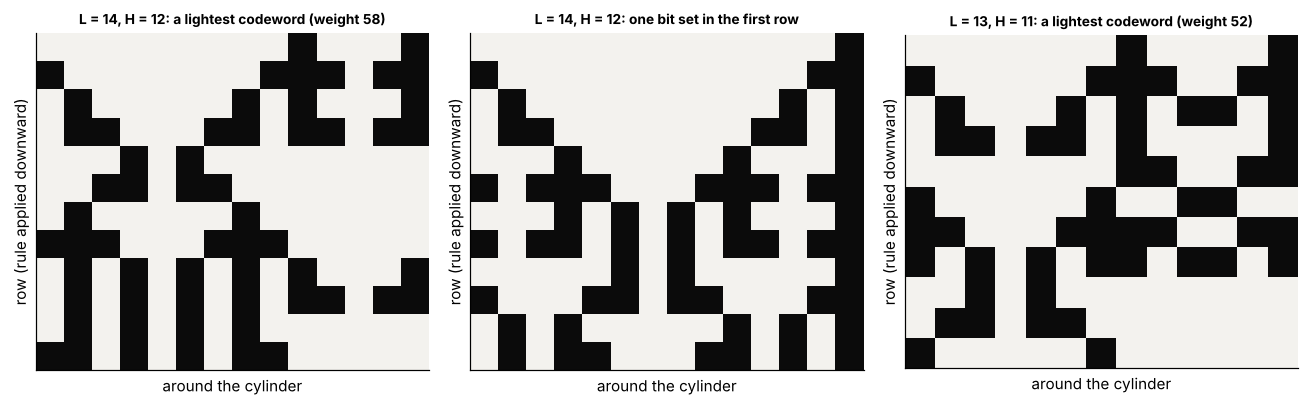

For most widths the distance grows much faster than the column height $H$ that a repetition code of the same rate
would have: $[80, 10, 26]$ against $d = 8$, and $[168, 14, 58]$ against $d = 12$. The rows with $L = 6$ and $L = 12$
show the catch: when $L$ is a multiple of 3, rule 150 has short periodic patterns on the cylinder and the distance
collapses to 4 or 8. **The shape of the chip matters**, and code design is a search over rules, sizes and boundaries.

## Part B2: sampled phase-flip noise

For larger codes we sample random phase flips and decode by maximum likelihood: compare the error with every one of the
$2^k$ codewords and pick the closest. (Ties are broken at random.) Each cellular-automaton code is compared with
$k$ separate repetition codes using the same $n$ and $k$.

sampled in 40 s


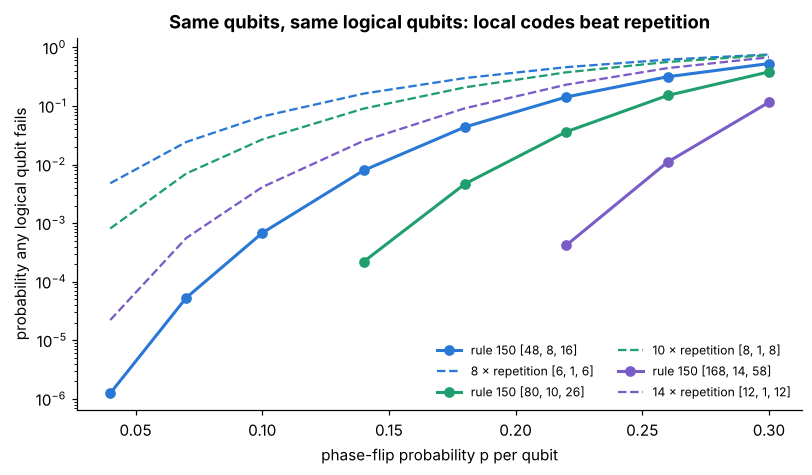

points with no failures in the sample are not drawn


Solid lines (cellular-automaton codes) sit well below dashed lines (repetition codes of the same size), and the gap
widens as the codes grow, because the distance grows faster. At high $p$ the curves approach each other: no code helps
once errors are dense.

## Part B3: the qubit bill

How many physical qubits (data plus one ancilla per check) does it take to store $k$ logical qubits with phase-flip
distance $d$?

* **surface code** on ordinary qubits: $k(2d^2 - 1)$, since it must also correct bit flips;
* **repetition cat**: $k(2d - 1)$;
* **rule-150 cat**: $n + (n - k)$ for the codes above.

,surface code (ordinary qubits),repetition cat,rule-150 cat,saving vs repetition cat
code,,,,
"[24, 4, 12]",1148,92,44,2.1
"[25, 5, 11]",1205,105,45,2.3
"[42, 7, 18]",4529,245,77,3.2
"[48, 8, 16]",4088,248,88,2.8
"[80, 10, 26]",13510,510,150,3.4
"[99, 11, 39]",33451,847,187,4.5
"[143, 13, 52]",70291,1339,273,4.9
"[168, 14, 58]",94178,1610,322,5.0


The first factor, surface code to repetition cat, is the payoff of biased noise: about 10 to 60 times fewer qubits
for these distances, growing with $d$. The second factor, repetition cat to a 2D local code, is the payoff of better
classical coding on top: another factor of about 2 to 5 for these sizes. (Both are code-capacity counts: they assume perfect check measurements and no
residual bit flips. Real proposals redo the comparison with full circuit noise, where the gains shrink but survive.)

## Part B4: magic states are a phase-flip problem too

Clifford gates alone cannot give a universal quantum computer. The missing ingredient is usually the T gate, supplied
by **magic states**, which are made noisy and then purified. In the classic **15-to-1** protocol (Bravyi and Kitaev),
15 noisy magic states enter a code, its 4 X-type checks are measured, and one better state comes out if all checks pass.
After a standard twirl, the noise on magic states is **only phase flips**, so the protocol is again a classical code:
the 4 checks are the columns of all nonzero 4-bit numbers, the **Hamming code** $[15, 11, 3]$.

An error pattern passes undetected if it is a Hamming codeword. It damages the output if it is an **odd-weight**
codeword (even-weight ones are harmless stabilisers). So, exactly,

$$p_\text{out} = \frac{\sum_{\text{odd codewords}} p^w(1-p)^{15-w}}{\sum_{\text{all codewords}} p^w(1-p)^{15-w}}.$$

undetected patterns: 2048 = 2^11; by weight: {0: 1, 3: 35, 4: 105, 5: 168, 6: 280, 7: 435, 8: 435, 9: 280, 10: 168, 11: 105, 12: 35, 15: 1}
harmful weight-3 patterns: 35  ->  p_out ≈ 35 p^3 for small p
p = 0.01: p_out = 3.609e-05 (35 p^3 = 3.500e-05), accepted 0.860
p = 0.001: p_out = 3.511e-08 (35 p^3 = 3.500e-08), accepted 0.985


The famous coefficient **35** is simply the number of weight-3 words of the Hamming code. Since the noise to be
removed is already one-sided, a biased-noise machine can run such protocols with cheap, bias-preserving operations,
which recent proposals push much further than the textbook 15-to-1 circuit.

## Animation: a local code at work

A rule-150 code on a 14 × 12 cylinder, $[168, 14, 58]$:

1. a codeword grows row by row from its first row;
2. phase flips strike (red outlines), with $p = 0.12$;
3. every check that sees an odd number of flips lights up (orange dots, drawn on the qubit each check ends at);
4. the decoder compares with all $2^{14}$ codewords and repairs the pattern.

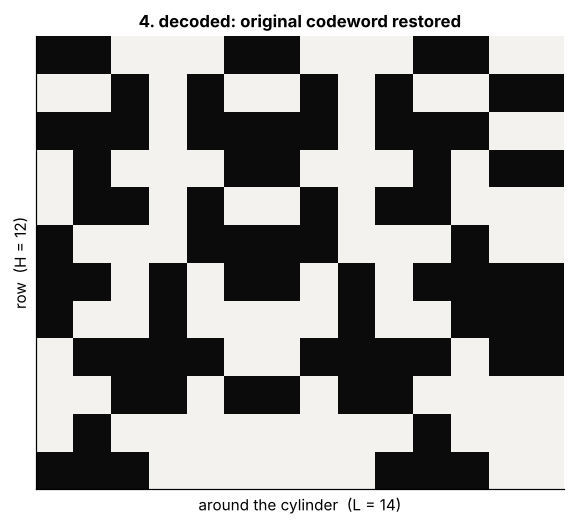

saved qe020_local_code.gif (2 s): 20 phase flips, 50 lit checks, recovered: True


**The animation** (embedded, so it plays on GitHub without running anything):

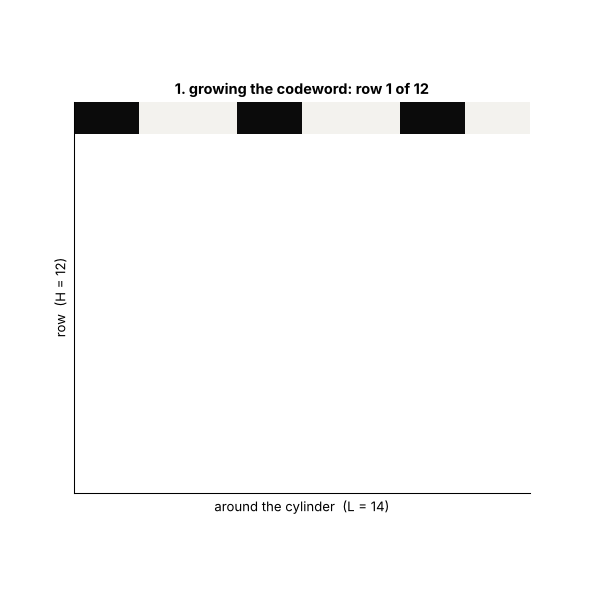

## Honest limits

* **Code capacity only.** Parts A and B2 assume perfect check measurements. Real syndrome extraction is noisy and must be
  repeated over time; local codes then need decoders that work on space-time patterns.
* **Bit flips are not zero.** Cat qubits make them rare, not absent; a finite photon number leaves a residual rate that
  a phase-flip-only code cannot fix, which sets a floor on the logical error.
* **Brute-force decoding** over $2^k$ codewords is fine for $k \le 14$ but impossible for real codes; practical decoders
  (belief propagation with ordered-statistics post-processing, union-find, matching) trade a little accuracy for speed.
* **Logical gates** on many logical qubits sharing one block are harder than on separate repetition codes; this is an
  active research area.

## Conclusions

1. **Stabiliser codes are bit tables.** A 60-line tableau simulator runs check-measurement circuits, and their outcomes
   match $He \bmod 2$ in every run.
2. **Biased noise halves the problem.** With cat qubits, X checks alone suffice and the quantum code becomes a
   classical code against phase flips.
3. **Exact answer.** The rule-150 cylinder code $[25, 5, 11]$ fails with probability
   $P_\text{fail} = 9.2105\times10^{-5}$ at $p = 1/20$ under ML decoding, so $A = 92104647$. That is about 60 times better than five repetition codes on the same 25 qubits.
4. **Local 2D codes beat lines.** Rule-150 codes reach $[168, 14, 58]$ with weight-4 checks, but the chip's width must
   avoid multiples of 3.
5. **Magic states fit the same picture.** 15-to-1 distillation is a classical code against phase flips; its
   coefficient 35 counts Hamming codewords.

**Try it yourself:** try other rules (the taps), open boundaries instead of a cylinder, add measurement errors by
repeating the syndrome, or search small rules for the best $k d^2 / n$ at fixed width.

### Further reading

* D. Gottesman, *Stabilizer codes and quantum error correction*, PhD thesis, Caltech (1997), arXiv:quant-ph/9705052.
* S. Aaronson, D. Gottesman, *Improved simulation of stabilizer circuits*, Phys. Rev. A 70, 052328 (2004).
* A. G. Fowler et al., *Surface codes: towards practical large-scale quantum computation*, Phys. Rev. A 86, 032324 (2012).
* J. Guillaud, M. Mirrahimi, *Repetition cat qubits for fault-tolerant quantum computation*, Phys. Rev. X 9, 041053 (2019).
* D. Ruiz, J. Guillaud, A. Leverrier, M. Mirrahimi, C. Vuillot, *LDPC-cat codes for low-overhead quantum computing in 2D*,
  Nature Communications (2025), arXiv:2401.09541.
* E. Huang, A. Pesah, C. T. Chubb, M. Vasmer, A. Dua, *Tailoring three-dimensional topological codes for biased noise*,
  Quantum (2023).
* S. Bravyi, A. Kitaev, *Universal quantum computation with ideal Clifford gates and noisy ancillas*,
  Phys. Rev. A 71, 022316 (2005).
* S. Wolfram, *Statistical mechanics of cellular automata*, Rev. Mod. Phys. 55, 601 (1983).